# Feature Scoring — Input × Outcome Importance Matrix

Uses `ema_workbench.analysis.feature_scoring` (Extra Trees) to
compute how much each uncertainty / lever drives each outcome.
Produces a heatmap: inputs on one axis, outcomes on the other,
cells coloured by importance score.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

In [2]:
FOLDER_NAME = "20260516_170952_scenario_elia_midterm"

# Outcomes to include in the heatmap (set to None for all scalar outcomes)
SELECTED_OUTCOMES = [
    "death_rate",
    "safe_rate",
    "death_rate_T1_BCAS",
    "death_rate_T2_BCAS",
    "death_rate_T3_BCAS",
    "mean_wait_care_T1_BCAS",
    "mean_wait_care_T2_BCAS",
    "mean_wait_care_T3_BCAS",
    "mean_wait_transport_T1_BCAS",
    "mean_wait_transport_T2_BCAS",
    "mean_wait_transport_T3_BCAS",
    "total_transport_time",
]


In [3]:
import pandas as pd
import numpy as np

run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME
df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df['scenario'].nunique()} scenarios  |  "
      f"{df['policy'].nunique()} distinct policies")

Loaded 16000 runs  |  4000 scenarios  |  320 distinct policies


In [4]:
# Columns before 'scenario' are inputs; after 'model' are outcomes.
meta_cols  = ["scenario", "policy", "model"]
meta_start = min(df.columns.get_loc(c) for c in meta_cols if c in df.columns)
input_cols = df.columns[:meta_start].tolist()
model_idx  = df.columns.get_loc("model")
outcome_cols = df.columns[model_idx + 1:].tolist()

print(f"Inputs  ({len(input_cols)}): {input_cols}")
print(f"Outcomes ({len(outcome_cols)}): {len(outcome_cols)} total")

if SELECTED_OUTCOMES is not None:
    outcome_cols = [c for c in SELECTED_OUTCOMES if c in outcome_cols]
    print(f"Selected {len(outcome_cols)} outcomes for scoring")

Inputs  (16): ['axp_r1_other_bde_min', 'axp_r1_same_bde_min', 'bcas_rate', 'ccp_r1_inter_bn_min', 'ccp_r1_same_bn_min', 'fraction_t1_bcas', 'fraction_t2_bcas', 'r1_r1_inter_bn_min', 'r1_r2_other_bde_min', 'r1_r2_same_bde_min', 'r2_r2_other_bde_min', 'seed', 'wave_duration_min', 'waves_per_day', 'ambulance_eligibility', 'facility_eligibility']
Outcomes (111): 111 total
Selected 12 outcomes for scoring


In [5]:
# x = inputs (uncertainties + levers), y = dict of outcome arrays
# Drop rows with NaN in any selected outcome
keep_cols = input_cols + outcome_cols
df_clean = df[keep_cols].dropna()
print(f"Kept {len(df_clean)}/{len(df)} rows after dropping NaN")

x = df_clean[input_cols].astype(float)
y = {col: df_clean[col].values for col in outcome_cols}

Kept 16000/16000 rows after dropping NaN


In [6]:
from ema_workbench.analysis import feature_scoring

scores = feature_scoring.get_feature_scores_all(x, y)
print(f"Score matrix shape: {scores.shape}")
print(f"Inputs: {list(scores.index)}")
print(f"Outcomes: {list(scores.columns)}")
scores

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Score matrix shape: (16, 12)
Inputs: ['ambulance_eligibility', 'axp_r1_other_bde_min', 'axp_r1_same_bde_min', 'bcas_rate', 'ccp_r1_inter_bn_min', 'ccp_r1_same_bn_min', 'facility_eligibility', 'fraction_t1_bcas', 'fraction_t2_bcas', 'r1_r1_inter_bn_min', 'r1_r2_other_bde_min', 'r1_r2_same_bde_min', 'r2_r2_other_bde_min', 'seed', 'wave_duration_min', 'waves_per_day']
Outcomes: ['death_rate', 'safe_rate', 'death_rate_T1_BCAS', 'death_rate_T2_BCAS', 'death_rate_T3_BCAS', 'mean_wait_care_T1_BCAS', 'mean_wait_care_T2_BCAS', 'mean_wait_care_T3_BCAS', 'mean_wait_transport_T1_BCAS', 'mean_wait_transport_T2_BCAS', 'mean_wait_transport_T3_BCAS', 'total_transport_time']


,death_rate,safe_rate,death_rate_T1_BCAS,death_rate_T2_BCAS,death_rate_T3_BCAS,mean_wait_care_T1_BCAS,mean_wait_care_T2_BCAS,mean_wait_care_T3_BCAS,mean_wait_transport_T1_BCAS,mean_wait_transport_T2_BCAS,mean_wait_transport_T3_BCAS,total_transport_time
0,,,,,,,,,,,,
ambulance_eligibility,0.004668,0.012252,0.012441,0.039674,0.0,0.051181,0.061358,0.051326,0.443581,0.044405,0.002759,0.094878
axp_r1_other_bde_min,0.008914,0.007935,0.009238,0.009081,0.0,0.017770,0.012351,0.011358,0.009101,0.023266,0.015030,0.006323
axp_r1_same_bde_min,0.009623,0.008505,0.008678,0.009306,0.0,0.017449,0.013326,0.011359,0.017092,0.023889,0.014869,0.006587
bcas_rate,0.417011,0.565263,0.626800,0.566129,0.0,0.430027,0.401885,0.360614,0.197300,0.376128,0.509430,0.702457
ccp_r1_inter_bn_min,0.009370,0.008386,0.008915,0.009653,0.0,0.019106,0.013698,0.010853,0.010256,0.022098,0.013462,0.006384
ccp_r1_same_bn_min,0.009657,0.009357,0.009990,0.011170,0.0,0.027986,0.022033,0.016338,0.038703,0.024647,0.015770,0.026113
facility_eligibility,0.001713,0.002203,0.003027,0.002730,0.0,0.021251,0.022009,0.042688,0.004366,0.005162,0.001967,0.002925
fraction_t1_bcas,0.381046,0.283199,0.185687,0.209437,0.0,0.061858,0.068407,0.186441,0.132901,0.045566,0.127502,0.068573
fraction_t2_bcas,0.085592,0.038379,0.058517,0.069952,0.0,0.096278,0.250998,0.195313,0.014985,0.180553,0.174101,0.018285


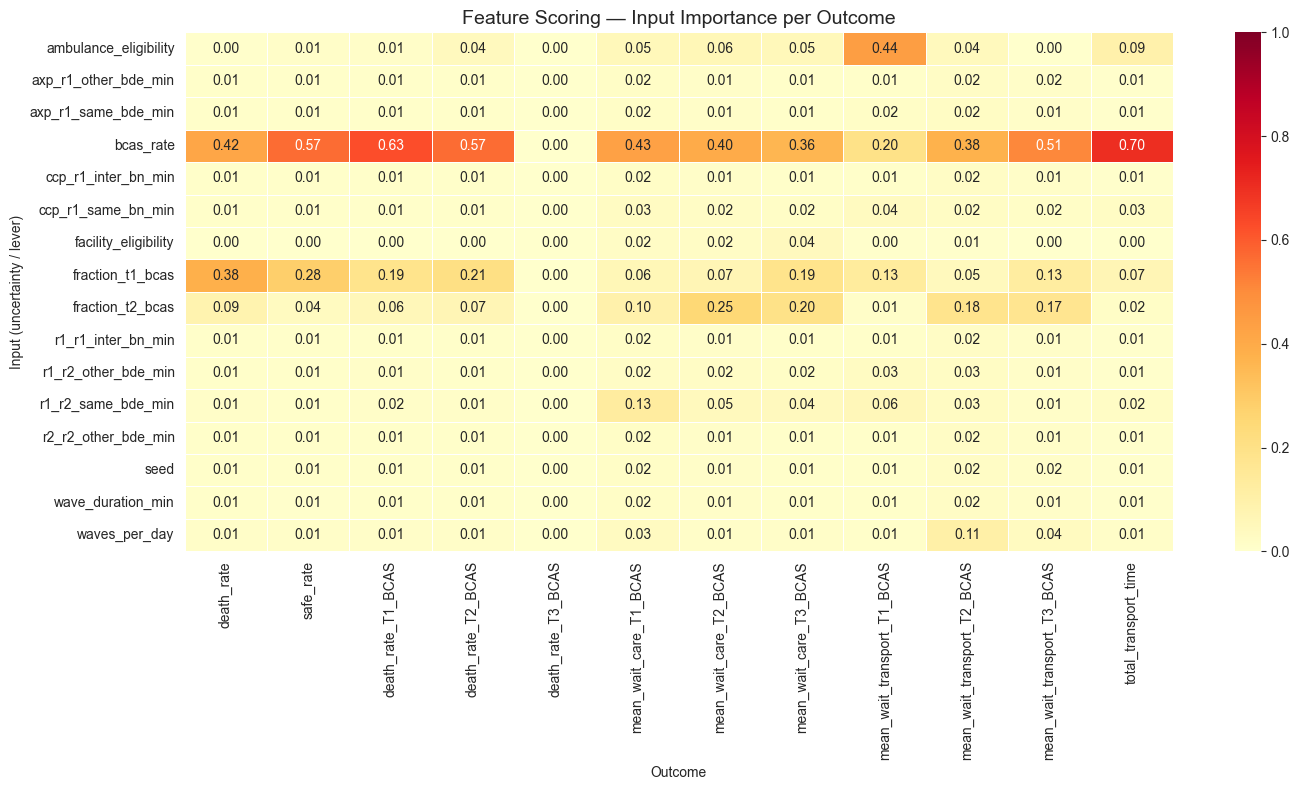

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(max(12, len(outcome_cols) * 1.2),
                                max(6, len(input_cols) * 0.5)))
sns.heatmap(
    scores,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax,
    vmin=0,
    vmax=1,
)
ax.set_title("Feature Scoring — Input Importance per Outcome", fontsize=14)
ax.set_xlabel("Outcome")
ax.set_ylabel("Input (uncertainty / lever)")
plt.tight_layout()
plt.show()

## Top inputs per outcome

For each outcome, list the inputs ranked by importance score.

In [8]:
TOP_N = 5

for outcome in scores.columns:
    ranked = scores[outcome].sort_values(ascending=False)
    print(f"\n{outcome}:")
    for i, (inp, sc) in enumerate(ranked.head(TOP_N).items()):
        bar = '█' * int(sc * 40)
        print(f"  {i+1}. {inp:35s} {sc:.3f}  {bar}")


death_rate:
  1. bcas_rate                           0.417  ████████████████
  2. fraction_t1_bcas                    0.381  ███████████████
  3. fraction_t2_bcas                    0.086  ███
  4. waves_per_day                       0.013  
  5. r1_r2_same_bde_min                  0.012  

safe_rate:
  1. bcas_rate                           0.565  ██████████████████████
  2. fraction_t1_bcas                    0.283  ███████████
  3. fraction_t2_bcas                    0.038  █
  4. ambulance_eligibility               0.012  
  5. waves_per_day                       0.012  

death_rate_T1_BCAS:
  1. bcas_rate                           0.627  █████████████████████████
  2. fraction_t1_bcas                    0.186  ███████
  3. fraction_t2_bcas                    0.059  ██
  4. r1_r2_same_bde_min                  0.015  
  5. waves_per_day                       0.013  

death_rate_T2_BCAS:
  1. bcas_rate                           0.566  ██████████████████████
  2. fraction_t1_bcas    

## Per-Policy Feature Scoring

Run feature scoring separately for each policy (lever combination)
to see whether input importance shifts across policies.

4 distinct policies:


,ambulance_eligibility,facility_eligibility
0,0,0
1,0,1
2,1,0
3,1,1


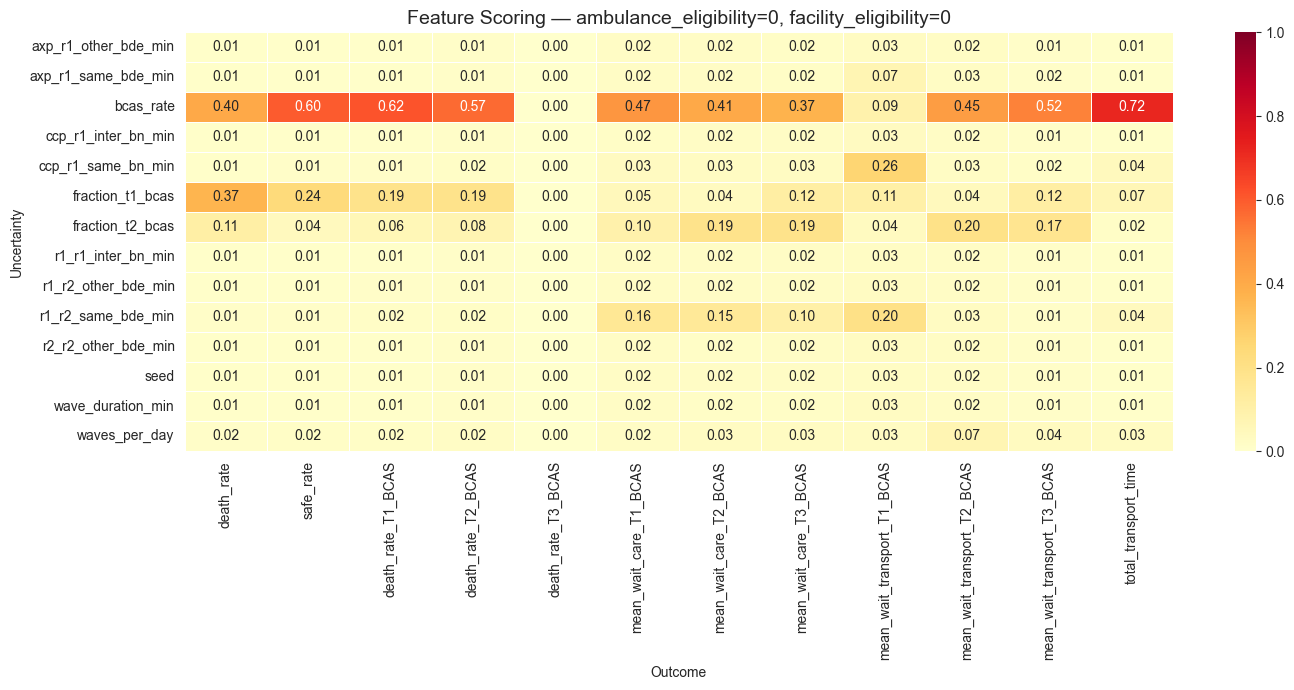

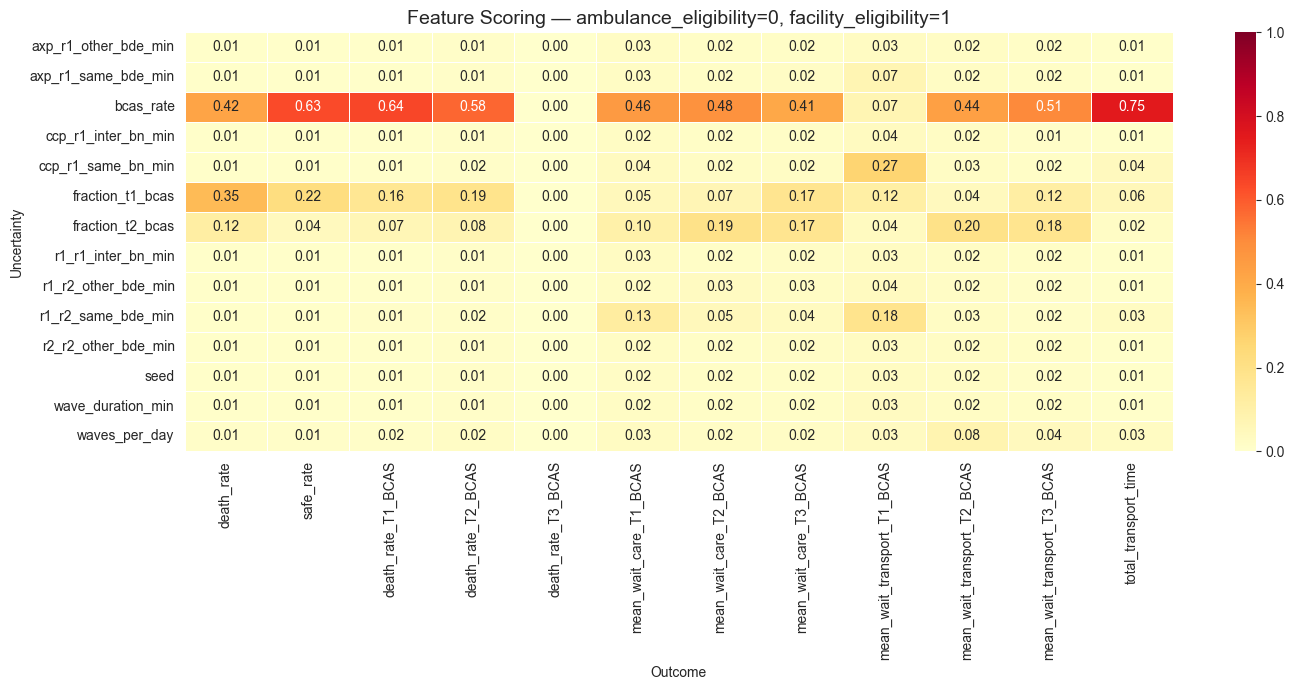

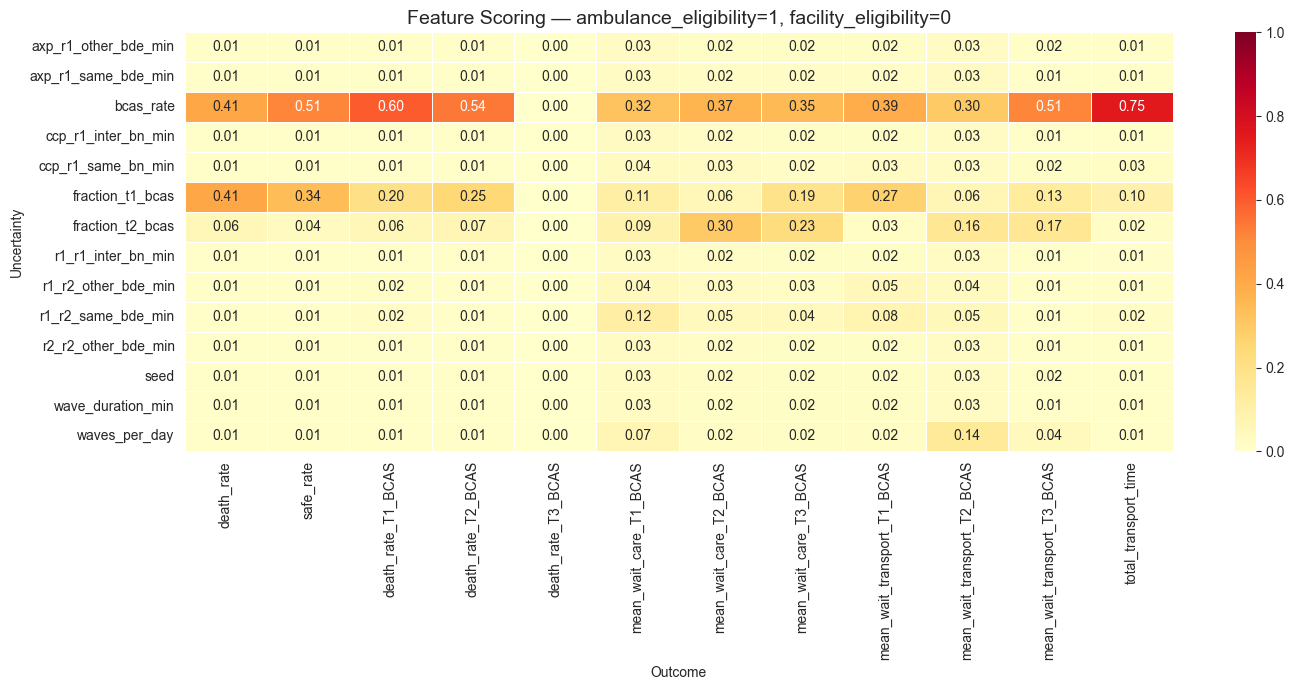

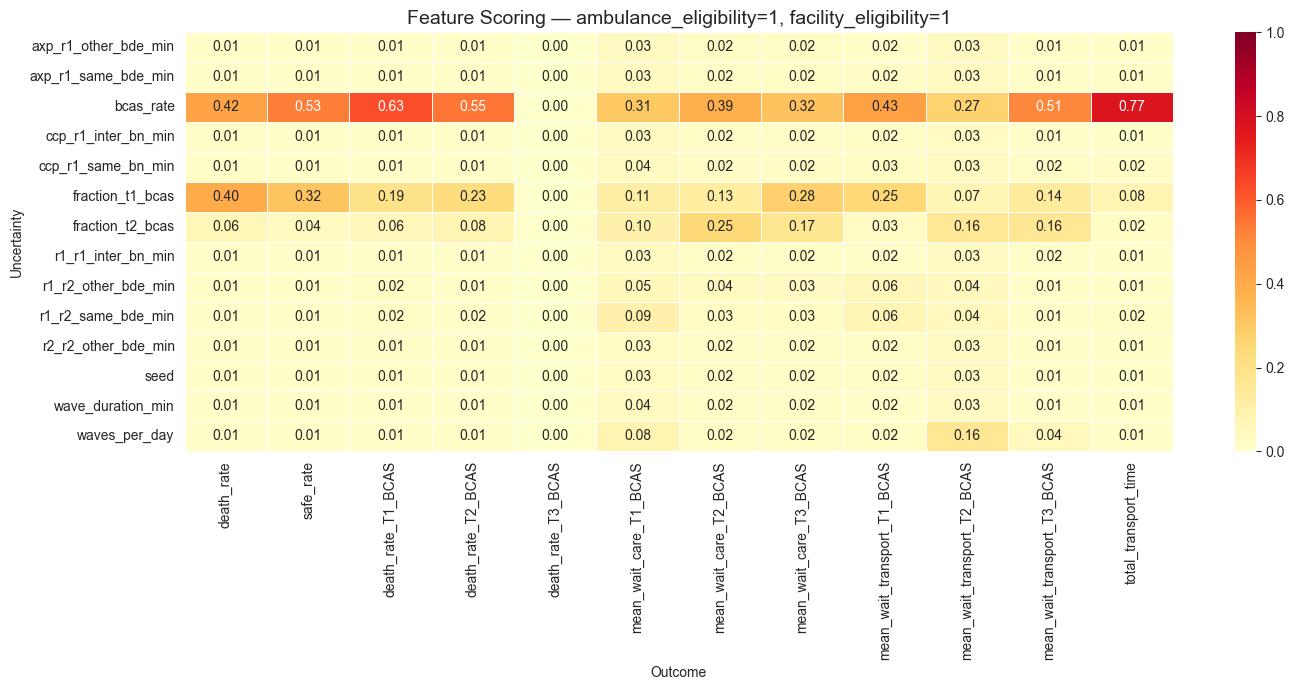

In [9]:
lever_cols = [c for c in input_cols if c in ["facility_eligibility", "ambulance_eligibility"]]
uncertainty_cols = [c for c in input_cols if c not in lever_cols]

policies = df[lever_cols].drop_duplicates().sort_values(lever_cols).reset_index(drop=True)
print(f"{len(policies)} distinct policies:")
display(policies)

for idx, policy_row in policies.iterrows():
    mask = pd.Series(True, index=df.index)
    for col in lever_cols:
        mask &= df[col] == policy_row[col]
    df_pol = df.loc[mask, uncertainty_cols + outcome_cols].dropna()
    
    x_pol = df_pol[uncertainty_cols].astype(float)
    y_pol = {col: df_pol[col].values for col in outcome_cols}
    
    scores_pol = feature_scoring.get_feature_scores_all(x_pol, y_pol)
    
    label = ", ".join(f"{c}={int(policy_row[c])}" for c in lever_cols)
    fig, ax = plt.subplots(figsize=(max(12, len(outcome_cols) * 1.2),
                                    max(6, len(uncertainty_cols) * 0.5)))
    sns.heatmap(
        scores_pol,
        annot=True,
        fmt=".2f",
        cmap="YlOrRd",
        linewidths=0.5,
        ax=ax,
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"Feature Scoring — {label}", fontsize=14)
    ax.set_xlabel("Outcome")
    ax.set_ylabel("Uncertainty")
    plt.tight_layout()
    plt.show()